<a href="https://colab.research.google.com/github/1900690/cucumber-bbox-datasetmanager/blob/main/cucumber_result.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving sorted_survey_result.csv to sorted_survey_result (1).csv
--- データの基本情報 ---


,調査日,発芽日,収穫日,試験区,調査回数,番号,長さ(cm),太さ(cm),曲がり(cm),推定重量(g),ランク,source_folder,source_file
0,2026-09-15,NaN,2026-09-15,8,1,1,20.5,2.8,0.5,111.0,AM,20260915,2026-09-15_2026-09-15_区8_1回目.csv
1,2026-09-15,NaN,2026-09-15,1,1,1,20.3,3.0,4.1,127.6,規格外,20260915,2026-09-15_2026-09-15_区1_1回目.csv
2,2026-09-15,NaN,2026-09-15,6,1,1,18.7,2.2,0.2,64.3,AM,20260915,2026-09-15_2026-09-15_区6_1回目.csv
3,2026-09-15,NaN,2026-09-15,6,1,2,18.7,2.4,2.9,75.6,BM,20260915,2026-09-15_2026-09-15_区6_1回目.csv
4,2026-09-15,NaN,2026-09-15,3,1,1,21.6,3.1,0.3,141.9,規格外,20260915,2026-09-15_2026-09-15_区3_1回目.csv


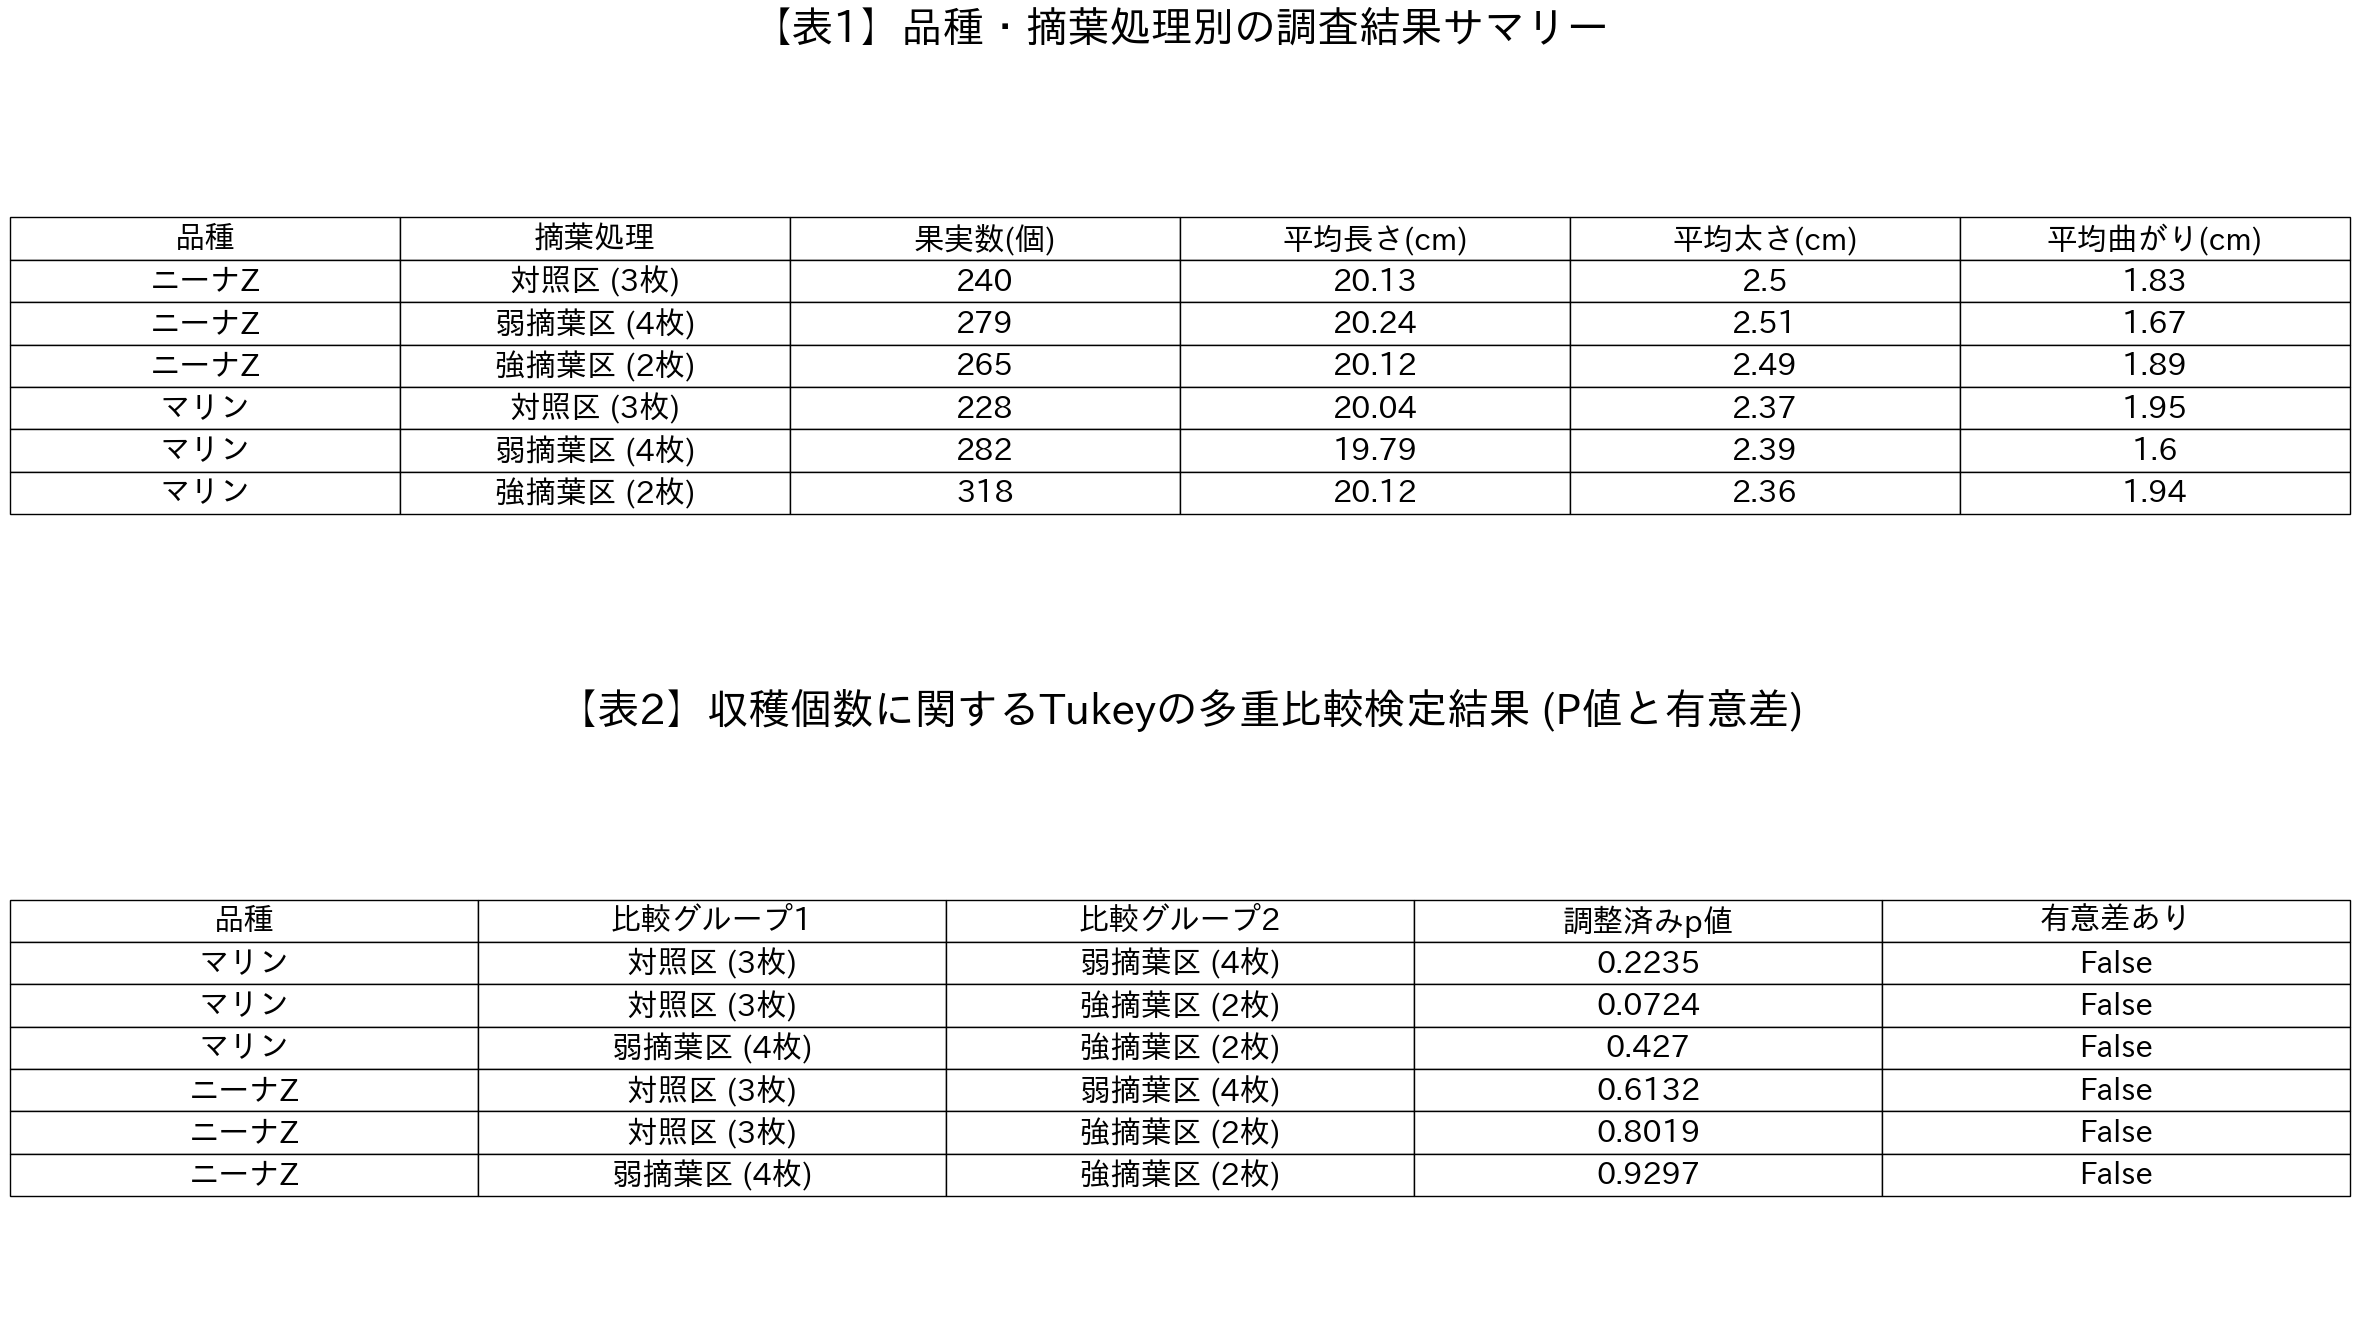

▶ 表の画像が 'survey_and_tukey_custom_tables_30pt.png' として保存されました。


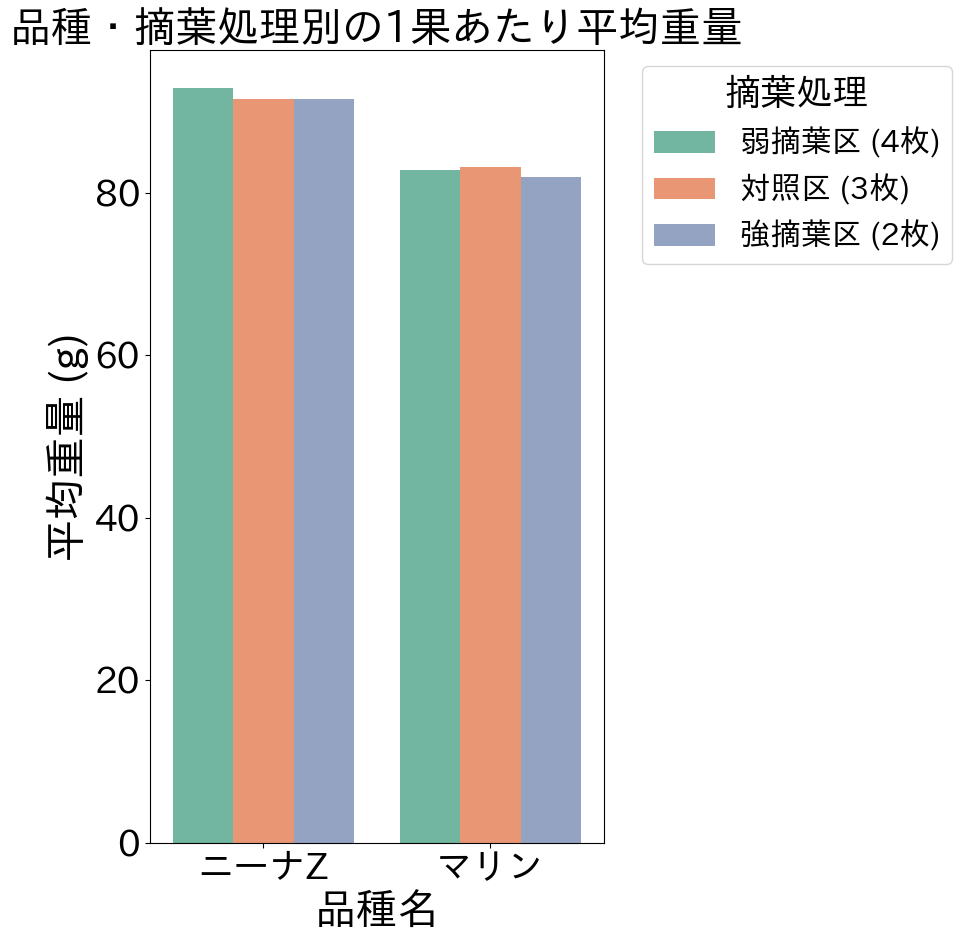

▶ 平均重量グラフの画像が 'bar_chart_weight_square_30pt.png' として保存されました。


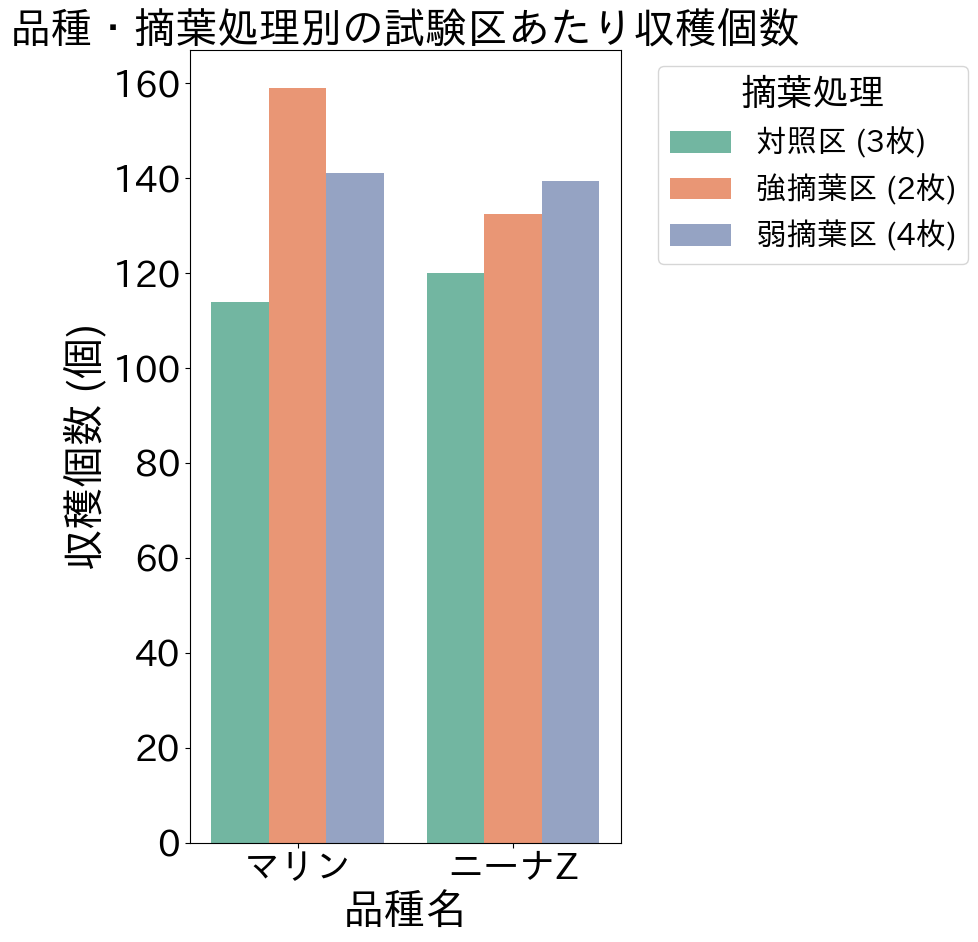

▶ 収穫個数グラフの画像が 'bar_chart_count_square_30pt.png' として保存されました。


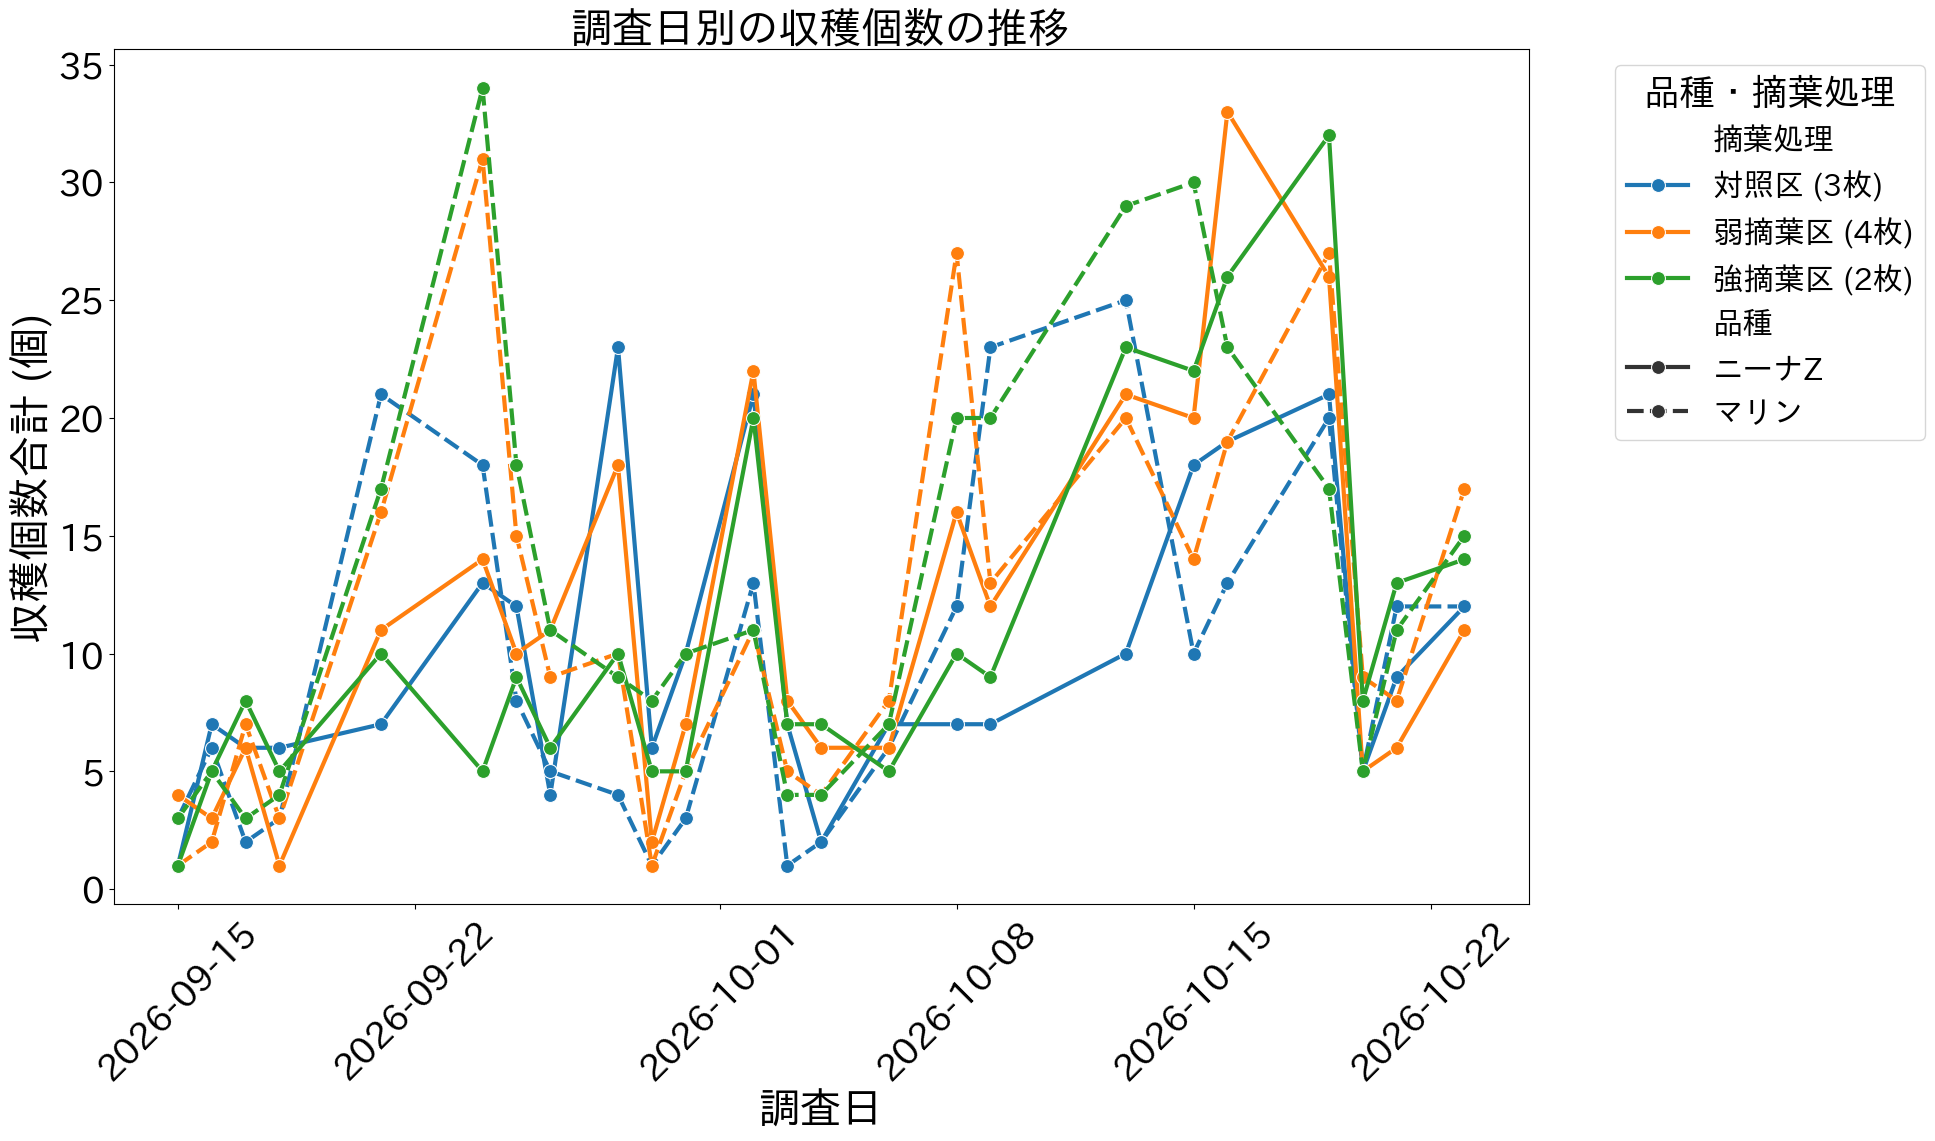

▶ 時系列グラフの画像が 'timeseries_count_chart_30pt.png' として保存されました。


In [2]:
# 1. 必要なライブラリのインポートと日本語フォントのインストール
!pip install japanize-matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# 2. CSVファイルのアップロード（Google Colab用）
from google.colab import files
uploaded = files.upload()

# アップロードされたファイル名を取得してデータフレームに読み込む
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("--- データの基本情報 ---")
display(df.head())

# 3. 品種と摘葉処理のマッピング関数
def assign_variety_and_treatment(df):
    def get_variety(sec):
        if sec in [1, 2, 3, 4, 5, 6]:
            return 'マリン'
        elif sec in [7, 8, 9, 10, 11, 12]:
            return 'ニーナZ'
        return '不明'

    def get_treatment(sec):
        if sec in [1, 6, 7, 12]:
            return '対照区 (3枚)'
        elif sec in [2, 3, 10, 11]:
            return '強摘葉区 (2枚)'
        elif sec in [4, 5, 8, 9]:
            return '弱摘葉区 (4枚)'
        return '不明'

    df['品種'] = df['試験区'].apply(get_variety)
    df['摘葉処理'] = df['試験区'].apply(get_treatment)
    return df

df = assign_variety_and_treatment(df)

# ==========================================
# 4. 文字サイズ（30pt相当）の一括設定
# ==========================================
plt.rcParams.update({
    'font.size': 26,
    'axes.labelsize': 30,
    'axes.titlesize': 30,
    'xtick.labelsize': 26,
    'ytick.labelsize': 26,
    'legend.fontsize': 22,
    'figure.titlesize': 30
})

# 5. 品種・摘葉処理ごとのサマリー集計（果実数、長さ、太さ、曲がり）
summary_df = df.groupby(['品種', '摘葉処理']).agg(
    果実数=('推定重量(g)', 'count'),
    平均長さ_cm=('長さ(cm)', 'mean'),
    平均太さ_cm=('太さ(cm)', 'mean'),
    平均曲がり_cm=('曲がり(cm)', 'mean')
).reset_index()

# 6. 試験区（反復）ごとの収穫個数を集計し、収穫個数に対するTukey検定を実行
plot_count = df.groupby(['試験区', '品種', '摘葉処理'])['推定重量(g)'].count().reset_index()
plot_count.rename(columns={'推定重量(g)': '収穫個数'}, inplace=True)

tukey_results = []
for variety in plot_count['品種'].unique():
    sub_df = plot_count[plot_count['品種'] == variety]
    tukey = pairwise_tukeyhsd(endog=sub_df['収穫個数'], groups=sub_df['摘葉処理'], alpha=0.05)

    t_df = pd.DataFrame(data=tukey.summary().data[1:], columns=tukey.summary().data[0])
    t_df = t_df[['group1', 'group2', 'p-adj', 'reject']]
    t_df.insert(0, '品種', variety)
    tukey_results.append(t_df)

tukey_count_df = pd.concat(tukey_results, ignore_index=True)
tukey_count_df.columns = ['品種', '比較グループ1', '比較グループ2', '調整済みp値', '有意差あり']
tukey_count_df['調整済みp値'] = tukey_count_df['調整済みp値'].round(4)

# ==========================================
# 7. 表（サマリー表＆収穫個数のTukey検定結果）の画像保存
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(24, 14))

ax1.axis('tight')
ax1.axis('off')
display_summary = summary_df[['品種', '摘葉処理', '果実数', '平均長さ_cm', '平均太さ_cm', '平均曲がり_cm']].copy()
display_summary.columns = ['品種', '摘葉処理', '果実数(個)', '平均長さ(cm)', '平均太さ(cm)', '平均曲がり(cm)']
display_summary = display_summary.round(2)

table1 = ax1.table(cellText=display_summary.values, colLabels=display_summary.columns, loc='center', cellLoc='center')
table1.auto_set_font_size(False)
table1.set_fontsize(22)
table1.scale(1.2, 2.2)
ax1.set_title('【表1】品種・摘葉処理別の調査結果サマリー', pad=30)

ax2.axis('tight')
ax2.axis('off')
table2 = ax2.table(cellText=tukey_count_df.values, colLabels=tukey_count_df.columns, loc='center', cellLoc='center')
table2.auto_set_font_size(False)
table2.set_fontsize(22)
table2.scale(1.2, 2.2)
ax2.set_title('【表2】収穫個数に関するTukeyの多重比較検定結果 (P値と有意差)', pad=30)

plt.tight_layout()
plt.savefig('survey_and_tukey_custom_tables_30pt.png', bbox_inches='tight', dpi=300)
plt.show()
print("▶ 表の画像が 'survey_and_tukey_custom_tables_30pt.png' として保存されました。")

# ==========================================
# 8-1. 平均重量のグラフ（独立した正方形画像として保存）
# ==========================================
plt.figure(figsize=(10, 10))
sns.barplot(data=df, x='品種', y='推定重量(g)', hue='摘葉処理', palette='Set2', errorbar=None)
plt.title('品種・摘葉処理別の1果あたり平均重量')
plt.ylabel('平均重量 (g)')
plt.xlabel('品種名')
plt.legend(title='摘葉処理', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('bar_chart_weight_square_30pt.png', bbox_inches='tight', dpi=300)
plt.show()
print("▶ 平均重量グラフの画像が 'bar_chart_weight_square_30pt.png' として保存されました。")

# ==========================================
# 8-2. 収穫個数のグラフ（独立した正方形画像として保存）
# ==========================================
plt.figure(figsize=(10, 10))
sns.barplot(data=plot_count, x='品種', y='収穫個数', hue='摘葉処理', palette='Set2', errorbar=None)
plt.title('品種・摘葉処理別の試験区あたり収穫個数')
plt.ylabel('収穫個数 (個)')
plt.xlabel('品種名')
plt.legend(title='摘葉処理', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('bar_chart_count_square_30pt.png', bbox_inches='tight', dpi=300)
plt.show()
print("▶ 収穫個数グラフの画像が 'bar_chart_count_square_30pt.png' として保存されました。")

# ==========================================
# 9. 時系列推移グラフの画像保存
# ==========================================
if '調査日' in df.columns:
    df['調査日'] = pd.to_datetime(df['調査日'].astype(str).str.replace('/', '-'), format='mixed')
    time_series = df.groupby(['調査日', '品種', '摘葉処理'])['推定重量(g)'].count().reset_index()
    time_series.rename(columns={'推定重量(g)': '収穫個数'}, inplace=True)

    plt.figure(figsize=(20, 12))
    sns.lineplot(data=time_series, x='調査日', y='収穫個数', hue='摘葉処理', style='品種', marker='o', linewidth=3, markersize=10)
    plt.title('調査日別の収穫個数の推移')
    plt.ylabel('収穫個数合計 (個)')
    plt.xlabel('調査日')
    plt.xticks(rotation=45)
    plt.legend(title='品種・摘葉処理', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig('timeseries_count_chart_30pt.png', bbox_inches='tight', dpi=300)
    plt.show()
    print("▶ 時系列グラフの画像が 'timeseries_count_chart_30pt.png' として保存されました。")

Saving sorted_survey_result.csv to sorted_survey_result (4).csv
--- 品種・摘葉処理別の発芽から収穫までの日数サマリー ---


,品種,摘葉処理,データ数,平均日数,最小日数,最大日数
0,ニーナZ,対照区 (3枚),11,17.9,11.0,24.0
1,ニーナZ,弱摘葉区 (4枚),17,14.5,8.0,28.0
2,ニーナZ,強摘葉区 (2枚),23,16.4,10.0,26.0
3,マリン,対照区 (3枚),16,15.4,10.0,24.0
4,マリン,弱摘葉区 (4枚),12,20.4,13.0,29.0
5,マリン,強摘葉区 (2枚),16,15.6,11.0,25.0


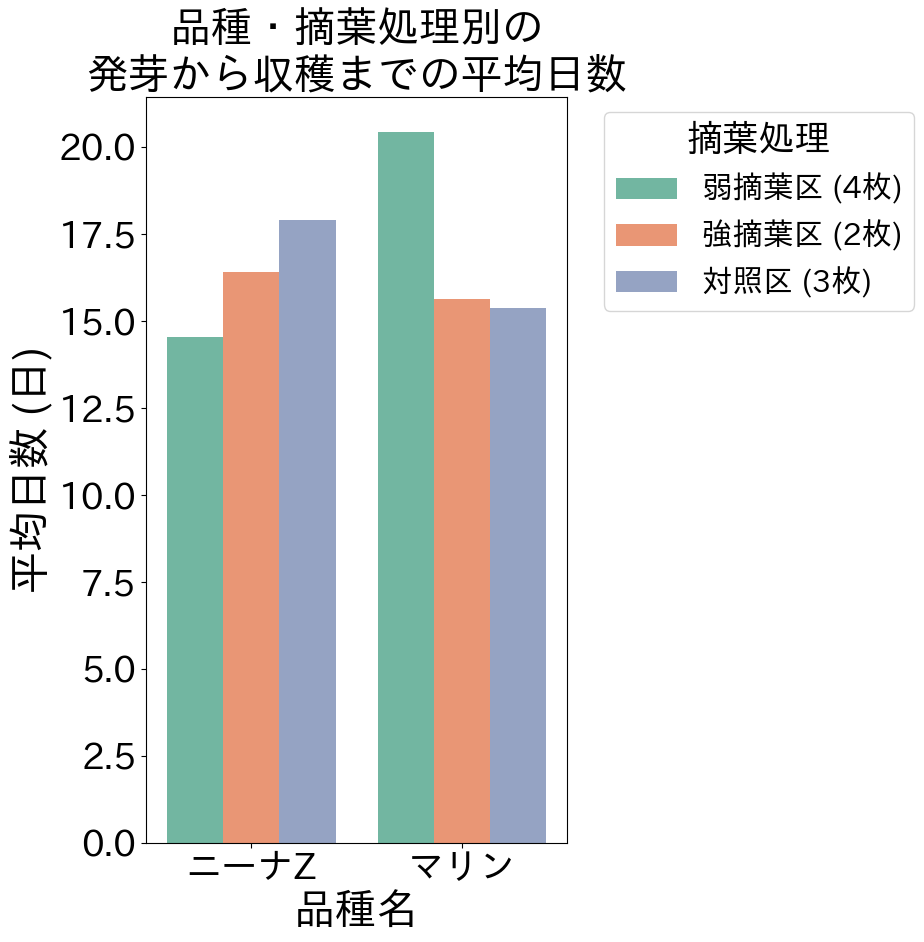

▶ 発芽から収穫までの平均日数グラフが 'days_from_germination_square_30pt.png' として保存されました。


In [5]:
# 1. 必要なライブラリのインポートと日本語フォントのインストール
!pip install japanize-matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib

# 2. CSVファイルのアップロード（Google Colab用）
from google.colab import files
uploaded = files.upload()

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

# 3. 品種と摘葉処理のマッピング関数
def assign_variety_and_treatment(df):
    def get_variety(sec):
        if sec in [1, 2, 3, 4, 5, 6]:
            return 'マリン'
        elif sec in [7, 8, 9, 10, 11, 12]:
            return 'ニーナZ'
        return '不明'

    def get_treatment(sec):
        if sec in [1, 6, 7, 12]:
            return '対照区 (3枚)'
        elif sec in [2, 3, 10, 11]:
            return '強摘葉区 (2枚)'
        elif sec in [4, 5, 8, 9]:
            return '弱摘葉区 (4枚)'
        return '不明'

    df['品種'] = df['試験区'].apply(get_variety)
    df['摘葉処理'] = df['試験区'].apply(get_treatment)
    return df

df = assign_variety_and_treatment(df)

# 4. 文字サイズ（30pt相当）の一括設定
plt.rcParams.update({
    'font.size': 26,
    'axes.labelsize': 30,
    'axes.titlesize': 30,
    'xtick.labelsize': 26,
    'ytick.labelsize': 26,
    'legend.fontsize': 22,
    'figure.titlesize': 30
})

# 5. 日付データの正規化と日数の計算
def parse_date(d_str):
    if pd.isna(d_str):
        return pd.NaT
    d_str = str(d_str).strip()
    if '月' in d_str and '日' in d_str:
        m = d_str.split('月')[0]
        d = d_str.split('月')[1].replace('日', '')
        return pd.to_datetime(f"2026-{int(m):02d}-{int(d):02d}")
    return pd.to_datetime(d_str.replace('/', '-'))

# 発芽データが存在する行を抽出
df_germ = df[df['発芽日'].notna()].copy()
df_germ['発芽日_dt'] = df_germ['発芽日'].apply(parse_date)
df_germ['収穫日_dt'] = df_germ['収穫日'].apply(parse_date)
df_germ['発芽から収穫までの日数'] = (df_germ['収穫日_dt'] - df_germ['発芽日_dt']).dt.days

# 集計サマリーの表示
days_summary = df_germ.groupby(['品種', '摘葉処理'])['発芽から収穫までの日数'].agg(
    データ数='count',
    平均日数='mean',
    最小日数='min',
    最大日数='max'
).reset_index().round(1)

print("--- 品種・摘葉処理別の発芽から収穫までの日数サマリー ---")
display(days_summary)

# ==========================================
# 6. 正方形のグラフの描画と画像保存
# ==========================================
plt.figure(figsize=(10, 10))
sns.barplot(
    data=df_germ,
    x='品種',
    y='発芽から収穫までの日数',
    hue='摘葉処理',
    palette='Set2',
    errorbar=None
)

plt.title('品種・摘葉処理別の\n発芽から収穫までの平均日数')
plt.ylabel('平均日数 (日)')
plt.xlabel('品種名')
plt.legend(title='摘葉処理', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig('days_from_germination_square_30pt.png', bbox_inches='tight', dpi=300)
plt.show()

print("▶ 発芽から収穫までの平均日数グラフが 'days_from_germination_square_30pt.png' として保存されました。")

Saving sorted_survey_result.csv to sorted_survey_result (5).csv
--- データの基本情報 ---


,調査日,発芽日,収穫日,試験区,調査回数,番号,長さ(cm),太さ(cm),曲がり(cm),推定重量(g),ランク,source_folder,source_file
0,2026-09-15,NaN,2026-09-15,8,1,1,20.5,2.8,0.5,111.0,AM,20260915,2026-09-15_2026-09-15_区8_1回目.csv
1,2026-09-15,NaN,2026-09-15,1,1,1,20.3,3.0,4.1,127.6,規格外,20260915,2026-09-15_2026-09-15_区1_1回目.csv
2,2026-09-15,NaN,2026-09-15,6,1,1,18.7,2.2,0.2,64.3,AM,20260915,2026-09-15_2026-09-15_区6_1回目.csv
3,2026-09-15,NaN,2026-09-15,6,1,2,18.7,2.4,2.9,75.6,BM,20260915,2026-09-15_2026-09-15_区6_1回目.csv
4,2026-09-15,NaN,2026-09-15,3,1,1,21.6,3.1,0.3,141.9,規格外,20260915,2026-09-15_2026-09-15_区3_1回目.csv


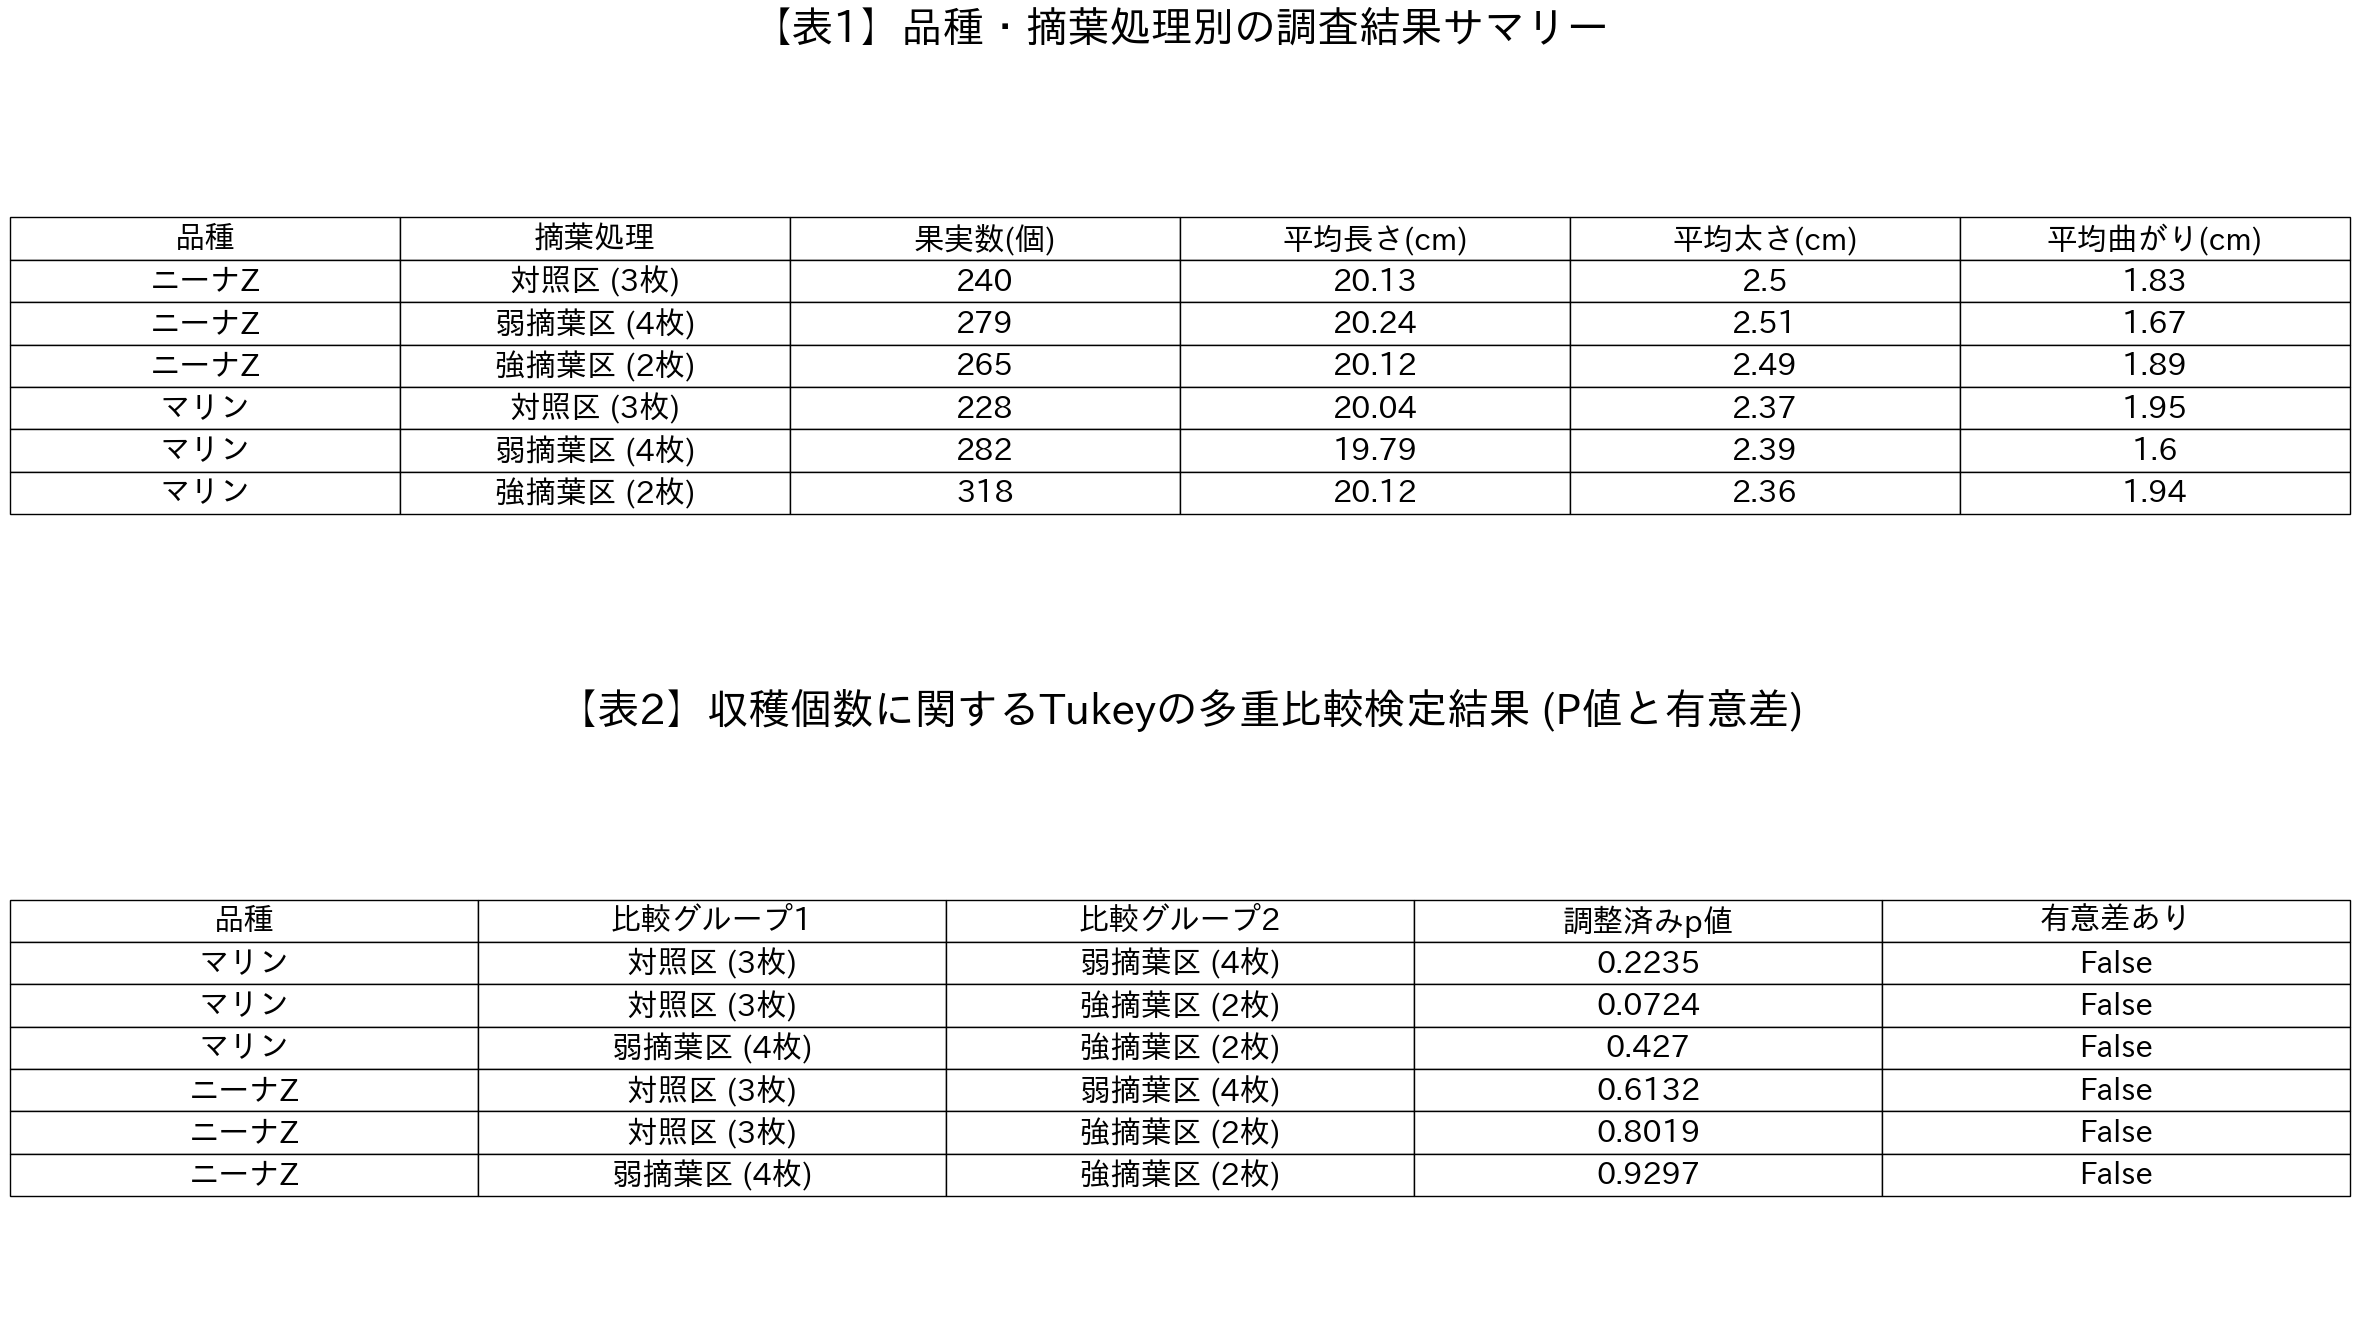

▶ 表の画像が 'survey_and_tukey_custom_tables_30pt.png' として保存されました。


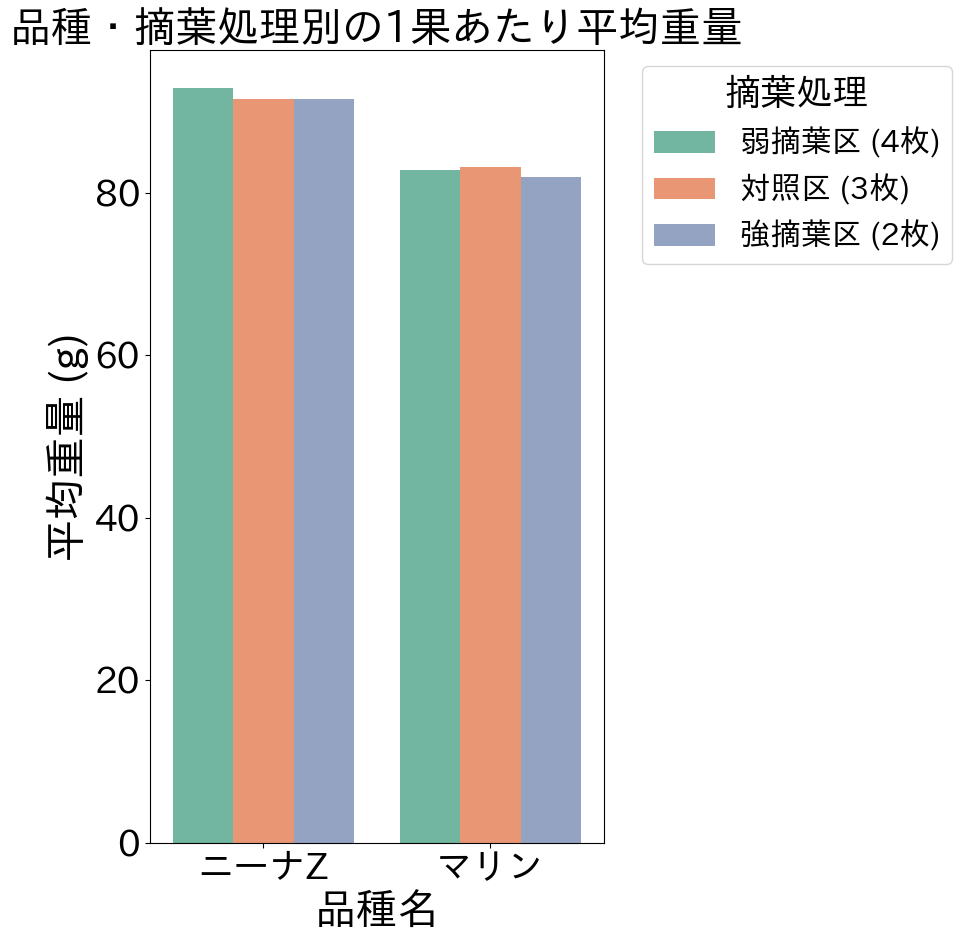

▶ 平均重量グラフの画像が 'bar_chart_weight_square_30pt.png' として保存されました。


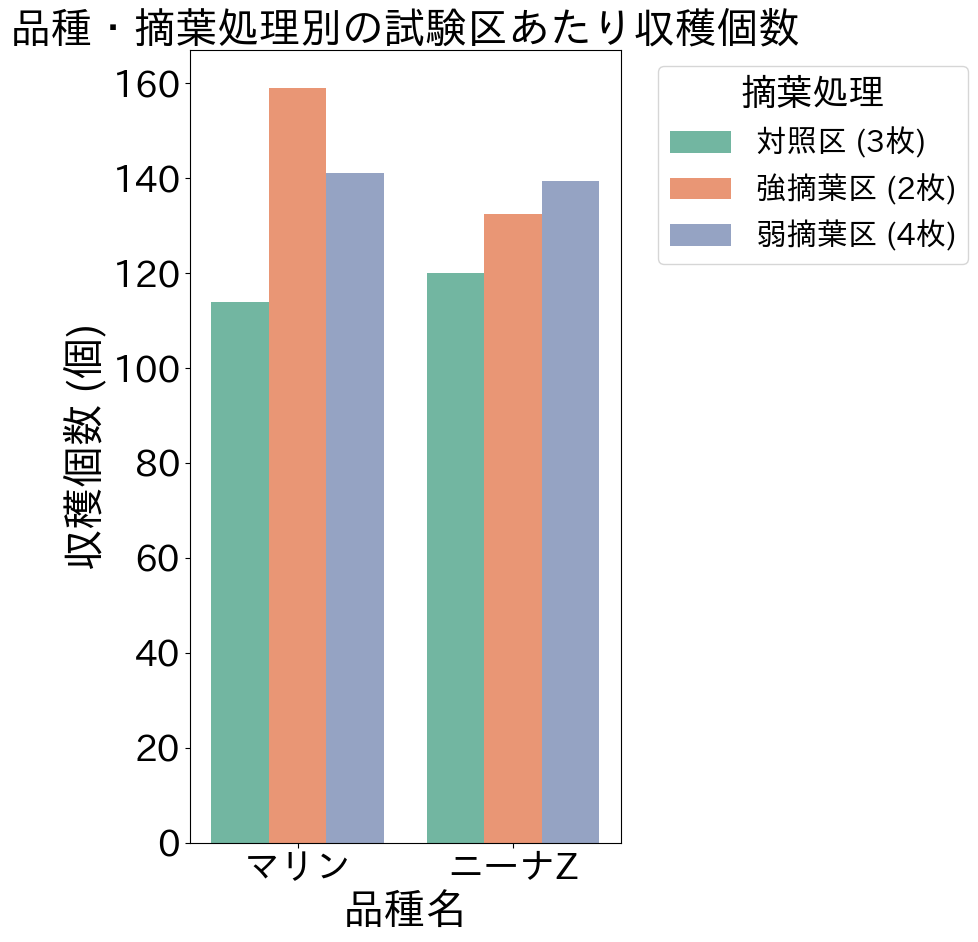

▶ 収穫個数グラフの画像が 'bar_chart_count_square_30pt.png' として保存されました。


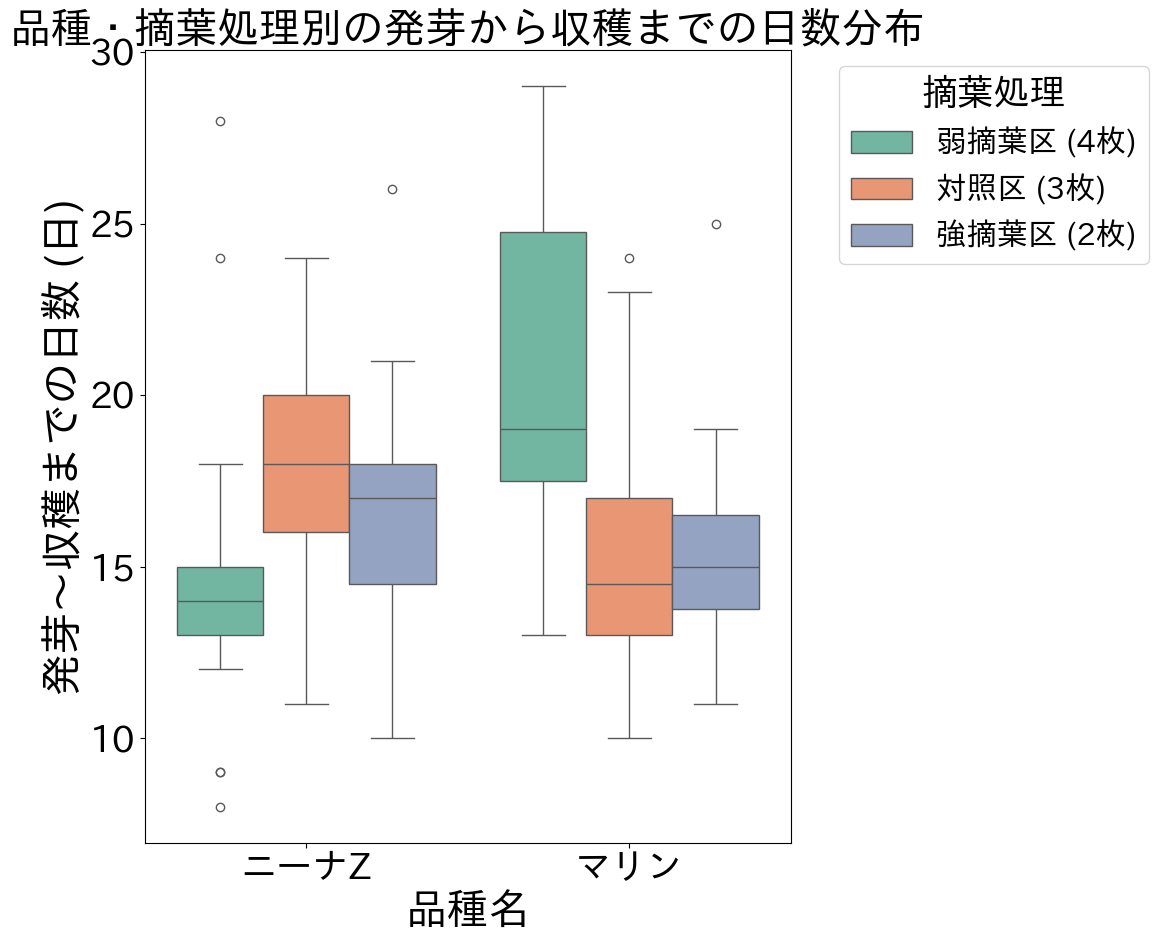

▶ 発芽〜収穫日数グラフの画像が 'days_to_harvest_box_30pt.png' として保存されました。


<Figure size 1200x1000 with 0 Axes>

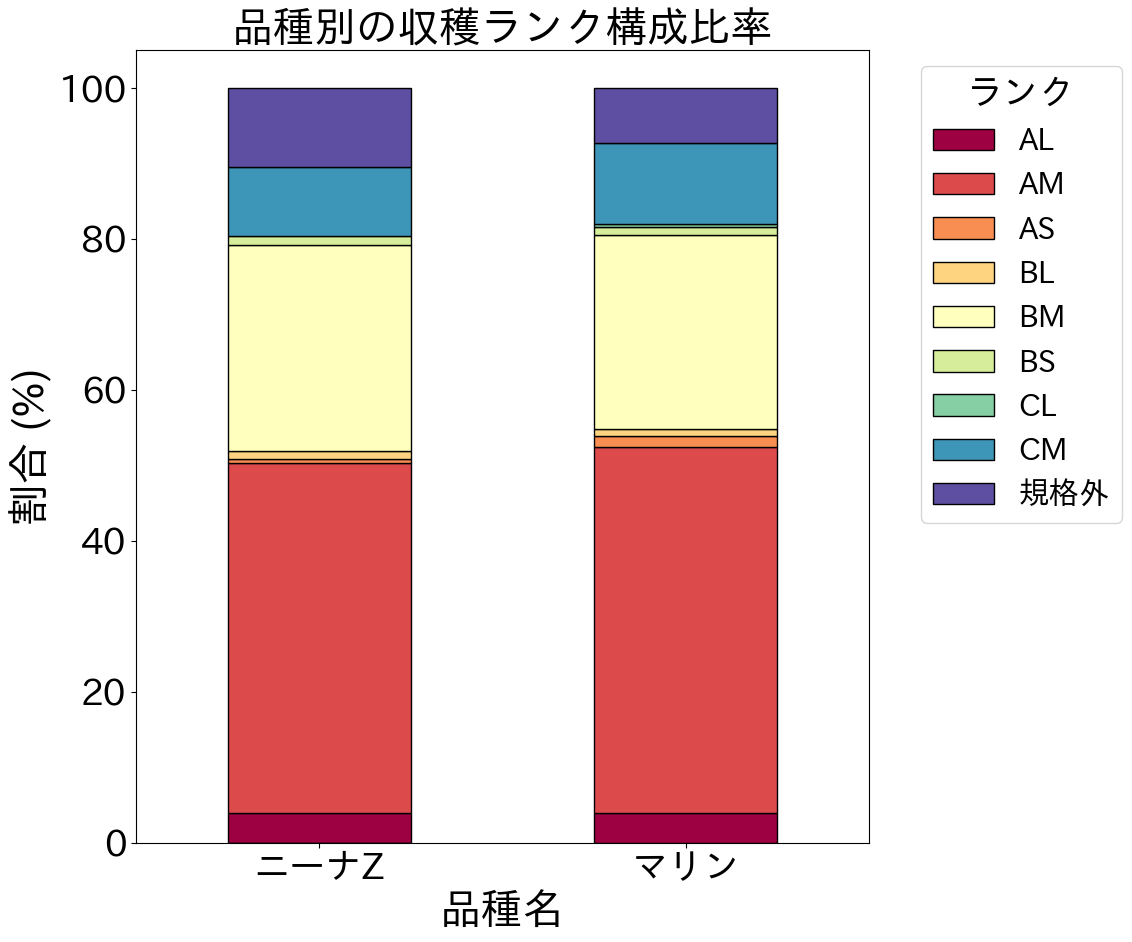

▶ ランク割合グラフの画像が 'variety_rank_stacked_bar_30pt.png' として保存されました。


In [6]:
# 1. 必要なライブラリのインポートと日本語フォントのインストール
!pip install japanize-matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# 2. CSVファイルのアップロード（Google Colab用）
from google.colab import files
uploaded = files.upload()

# アップロードされたファイル名を取得してデータフレームに読み込む
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("--- データの基本情報 ---")
display(df.head())

# 3. 品種と摘葉処理のマッピング関数
def assign_variety_and_treatment(df):
    def get_variety(sec):
        if sec in [1, 2, 3, 4, 5, 6]:
            return 'マリン'
        elif sec in [7, 8, 9, 10, 11, 12]:
            return 'ニーナZ'
        return '不明'

    def get_treatment(sec):
        if sec in [1, 6, 7, 12]:
            return '対照区 (3枚)'
        elif sec in [2, 3, 10, 11]:
            return '強摘葉区 (2枚)'
        elif sec in [4, 5, 8, 9]:
            return '弱摘葉区 (4枚)'
        return '不明'

    df['品種'] = df['試験区'].apply(get_variety)
    df['摘葉処理'] = df['試験区'].apply(get_treatment)
    return df

df = assign_variety_and_treatment(df)

# ==========================================
# 4. 文字サイズ（30pt相当）の一括設定
# ==========================================
plt.rcParams.update({
    'font.size': 26,
    'axes.labelsize': 30,
    'axes.titlesize': 30,
    'xtick.labelsize': 26,
    'ytick.labelsize': 26,
    'legend.fontsize': 22,
    'figure.titlesize': 30
})

# ==========================================
# 5. 日付データのクリーニング ＆ 発芽〜収穫日数の算出
# ==========================================
def parse_date(val):
    if pd.isnull(val):
        return pd.NaT
    val_str = str(val).strip()
    if '月' in val_str and '日' in val_str:
        val_str = val_str.replace('月', '-').replace('日', '')
        val_str = f"2026-{val_str}"
    return pd.to_datetime(val_str, errors='coerce', format='mixed')

df['発芽日_dt'] = df['発芽日'].apply(parse_date)
df['収穫日_dt'] = df['収穫日'].apply(parse_date)
df['発芽から収穫までの日数'] = (df['収穫日_dt'] - df['発芽日_dt']).dt.days

# ==========================================
# 6. 表用のデータ集計（サマリー＆Tukey検定）
# ==========================================
summary_df = df.groupby(['品種', '摘葉処理']).agg(
    果実数=('推定重量(g)', 'count'),
    平均長さ_cm=('長さ(cm)', 'mean'),
    平均太さ_cm=('太さ(cm)', 'mean'),
    平均曲がり_cm=('曲がり(cm)', 'mean')
).reset_index()

plot_count = df.groupby(['試験区', '品種', '摘葉処理'])['推定重量(g)'].count().reset_index()
plot_count.rename(columns={'推定重量(g)': '収穫個数'}, inplace=True)

tukey_results = []
for variety in plot_count['品種'].unique():
    sub_df = plot_count[plot_count['品種'] == variety]
    tukey = pairwise_tukeyhsd(endog=sub_df['収穫個数'], groups=sub_df['摘葉処理'], alpha=0.05)

    t_df = pd.DataFrame(data=tukey.summary().data[1:], columns=tukey.summary().data[0])
    t_df = t_df[['group1', 'group2', 'p-adj', 'reject']]
    t_df.insert(0, '品種', variety)
    tukey_results.append(t_df)

tukey_count_df = pd.concat(tukey_results, ignore_index=True)
tukey_count_df.columns = ['品種', '比較グループ1', '比較グループ2', '調整済みp値', '有意差あり']
tukey_count_df['調整済みp値'] = tukey_count_df['調整済みp値'].round(4)

# ==========================================
# 7. 表（サマリー表＆収穫個数のTukey検定結果）の画像保存
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(24, 14))

ax1.axis('tight')
ax1.axis('off')
display_summary = summary_df[['品種', '摘葉処理', '果実数', '平均長さ_cm', '平均太さ_cm', '平均曲がり_cm']].copy()
display_summary.columns = ['品種', '摘葉処理', '果実数(個)', '平均長さ(cm)', '平均太さ(cm)', '平均曲がり(cm)']
display_summary = display_summary.round(2)

table1 = ax1.table(cellText=display_summary.values, colLabels=display_summary.columns, loc='center', cellLoc='center')
table1.auto_set_font_size(False)
table1.set_fontsize(22)
table1.scale(1.2, 2.2)
ax1.set_title('【表1】品種・摘葉処理別の調査結果サマリー', pad=30)

ax2.axis('tight')
ax2.axis('off')
table2 = ax2.table(cellText=tukey_count_df.values, colLabels=tukey_count_df.columns, loc='center', cellLoc='center')
table2.auto_set_font_size(False)
table2.set_fontsize(22)
table2.scale(1.2, 2.2)
ax2.set_title('【表2】収穫個数に関するTukeyの多重比較検定結果 (P値と有意差)', pad=30)

plt.tight_layout()
plt.savefig('survey_and_tukey_custom_tables_30pt.png', bbox_inches='tight', dpi=300)
plt.show()
print("▶ 表の画像が 'survey_and_tukey_custom_tables_30pt.png' として保存されました。")

# ==========================================
# 8-1. 平均重量のグラフ（正方形画像）
# ==========================================
plt.figure(figsize=(10, 10))
sns.barplot(data=df, x='品種', y='推定重量(g)', hue='摘葉処理', palette='Set2', errorbar=None)
plt.title('品種・摘葉処理別の1果あたり平均重量')
plt.ylabel('平均重量 (g)')
plt.xlabel('品種名')
plt.legend(title='摘葉処理', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('bar_chart_weight_square_30pt.png', bbox_inches='tight', dpi=300)
plt.show()
print("▶ 平均重量グラフの画像が 'bar_chart_weight_square_30pt.png' として保存されました。")

# ==========================================
# 8-2. 収穫個数のグラフ（正方形画像）
# ==========================================
plt.figure(figsize=(10, 10))
sns.barplot(data=plot_count, x='品種', y='収穫個数', hue='摘葉処理', palette='Set2', errorbar=None)
plt.title('品種・摘葉処理別の試験区あたり収穫個数')
plt.ylabel('収穫個数 (個)')
plt.xlabel('品種名')
plt.legend(title='摘葉処理', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('bar_chart_count_square_30pt.png', bbox_inches='tight', dpi=300)
plt.show()
print("▶ 収穫個数グラフの画像が 'bar_chart_count_square_30pt.png' として保存されました。")

# ==========================================
# 8-3. 【新規】発芽から収穫までの期間（日数）の分布グラフ
# ==========================================
plt.figure(figsize=(12, 10))
sns.boxplot(data=df, x='品種', y='発芽から収穫までの日数', hue='摘葉処理', palette='Set2')
plt.title('品種・摘葉処理別の発芽から収穫までの日数分布')
plt.ylabel('発芽〜収穫までの日数 (日)')
plt.xlabel('品種名')
plt.legend(title='摘葉処理', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('days_to_harvest_box_30pt.png', bbox_inches='tight', dpi=300)
plt.show()
print("▶ 発芽〜収穫日数グラフの画像が 'days_to_harvest_box_30pt.png' として保存されました。")

# ==========================================
# 8-4. 【新規】品種ごとのランク割合（積み上げ棒グラフ）
# ==========================================
rank_crosstab = pd.crosstab(df['品種'], df['ランク'], normalize='index') * 100

plt.figure(figsize=(12, 10))
rank_crosstab.plot(kind='bar', stacked=True, colormap='Spectral', figsize=(12, 10), edgecolor='black')
plt.title('品種別の収穫ランク構成比率')
plt.ylabel('割合 (%)')
plt.xlabel('品種名')
plt.xticks(rotation=0)
plt.legend(title='ランク', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('variety_rank_stacked_bar_30pt.png', bbox_inches='tight', dpi=300)
plt.show()
print("▶ ランク割合グラフの画像が 'variety_rank_stacked_bar_30pt.png' として保存されました。")